In [8]:
!pip install keras-tuner

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [keras-tuner]


In [14]:
!pip install pgmpy networkx matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 14.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [pgmpy]


MODEL VALIDATION
True

GENERATED SAMPLES
   Rain  WetGrass  Sprinkler
0     0         0          0
1     1         1          0
2     1         1          1
3     0         1          1
4     0         0          1
5     0         1          1
6     0         1          1
7     1         1          1
8     0         0          0
9     1         1          0

SAMPLE DATASET
   Rain  WetGrass  Sprinkler
0     0         0          0
1     1         1          0
2     1         1          1
3     0         1          1
4     0         0          1

PROBABILITY DISTRIBUTIONS

 Rain
Rain
0    0.712
1    0.288
Name: proportion, dtype: float64

 WetGrass
WetGrass
1    0.512
0    0.488
Name: proportion, dtype: float64

 Sprinkler
Sprinkler
0    0.57
1    0.43
Name: proportion, dtype: float64

P(RAIN | WET GRASS)
+---------+-------------+
| Rain    |   phi(Rain) |
+=========+=============+
| Rain(0) |      0.4437 |
+---------+-------------+
| Rain(1) |      0.5563 |
+---------+-------------+

Es

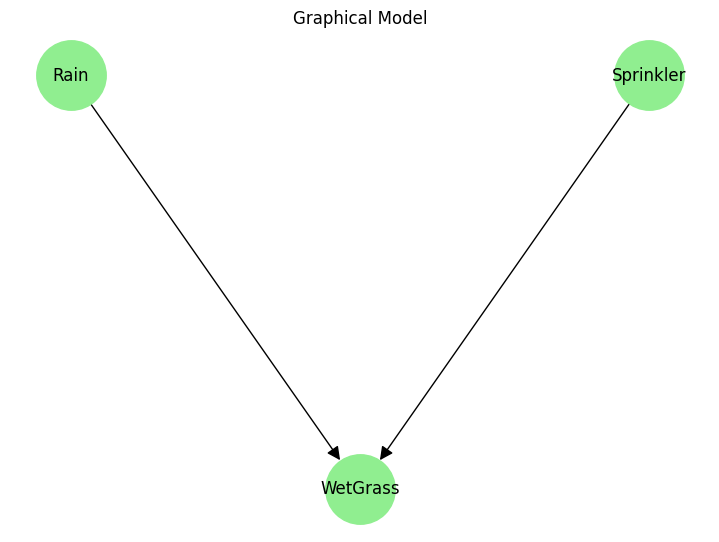

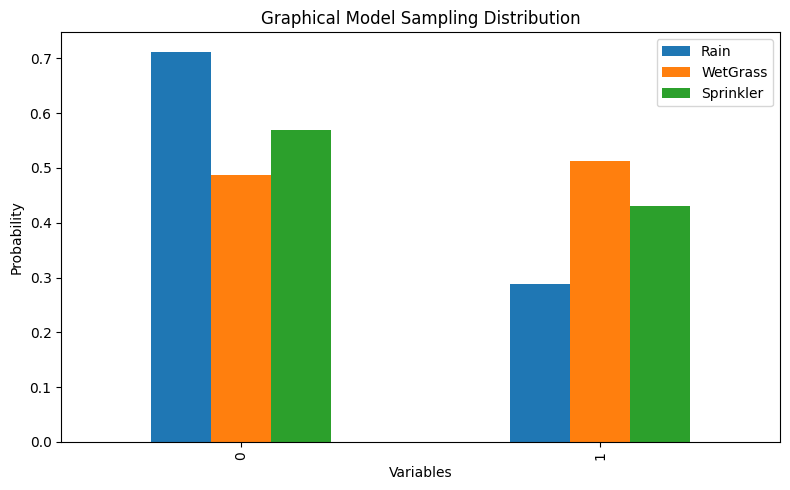

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.factors.discrete import TabularCPD
from pgmpy.inference import VariableElimination
from pgmpy.sampling import BayesianModelSampling

# 1. Create Bayesian Network
model = DiscreteBayesianNetwork([
    ("Rain", "WetGrass"),
    ("Sprinkler", "WetGrass")
])

# 2. Define probability distributions
cpd_rain = TabularCPD(
    variable="Rain",
    variable_card=2,
    values=[[0.7], [0.3]]
)

cpd_sprinkler = TabularCPD(
    variable="Sprinkler",
    variable_card=2,
    values=[[0.6], [0.4]]
)

cpd_wetgrass = TabularCPD(
    variable="WetGrass",
    variable_card=2,
    values=[
        [1.0, 0.2, 0.1, 0.01],
        [0.0, 0.8, 0.9, 0.99]
    ],
    evidence=["Rain", "Sprinkler"],
    evidence_card=[2, 2]
)

# 3. Add CPDs
model.add_cpds(
    cpd_rain,
    cpd_sprinkler,
    cpd_wetgrass
)

# 4. Validate model
print("MODEL VALIDATION")

print(model.check_model())

# 5. Generate samples
sampler = BayesianModelSampling(model)

samples = sampler.forward_sample(
    size=1000,
    seed=42,
    show_progress=False
)

print("\nGENERATED SAMPLES")

print(samples.head(10))

# 6. Convert samples to DataFrame
df = pd.DataFrame(samples)

print("\nSAMPLE DATASET")

print(df.head())

# 7. Calculate probabilities
print("\nPROBABILITY DISTRIBUTIONS")

for column in df.columns:

    print("\n", column)

    print(
        df[column].value_counts(
            normalize=True
        )
    )

# 8. Probabilistic inference
inference = VariableElimination(model)

result = inference.query(
    variables=["Rain"],
    evidence={"WetGrass": 1}
)

print("\nP(RAIN | WET GRASS)")

print(result)

# 9. Calculate conditional probability from samples
conditional = df[
    df["WetGrass"] == 1
]["Rain"].mean()

print(
    "\nEstimated P(Rain=1 | WetGrass=1):",
    conditional
)

# 10. Visualize graphical model
G = nx.DiGraph()

G.add_edges_from(model.edges())

pos = {
    "Rain": (0, 1),
    "Sprinkler": (2, 1),
    "WetGrass": (1, 0)
}

plt.figure(figsize=(7, 5))

nx.draw(
    G,
    pos,
    with_labels=True,
    node_size=2500,
    node_color="lightgreen",
    arrows=True,
    arrowsize=20
)

plt.title("Graphical Model")

plt.axis("off")

plt.show()

# 11. Plot sample distributions
df.apply(
    lambda col: col.value_counts(normalize=True)
).plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Graphical Model Sampling Distribution")

plt.xlabel("Variables")

plt.ylabel("Probability")

plt.tight_layout()

plt.show()